# Segmentación de clientes de un centro comercial: implementación (EP5)
**Grupo 3 · SCY1102 Gestión de Proyectos de Datos · Sección 002V**
Alejandro Cáceres (JP) · Cristian Chicaisa (DE) · Eduardo Sajnovich (DS) · Stanley Joseph (BI)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Sajnovich/segmentacion-clientes-mall/blob/main/notebooks/EP5_Segmentacion_Clientes.ipynb)

Este notebook implementa las fases 2 a 6 de CRISP-DM del plan de la EP3. Cada sección indica el sprint,
el entregable (E) y la puerta de calidad (G) que respalda. La lógica reutilizable vive en `src/segmentacion.py`
y el pipeline completo se ejecuta con `python src/pipeline.py`. En Google Colab, la primera celda descarga
el repositorio, así que basta con **Entorno de ejecución > Ejecutar todas**.

In [1]:
import sys, json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

# En Google Colab se descarga el repositorio; en un computador se usa la carpeta del proyecto
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    RAIZ = Path('/content/segmentacion-clientes-mall')
    if not RAIZ.exists():
        subprocess.run(['git', 'clone', '-q', 'https://github.com/Sajnovich/segmentacion-clientes-mall.git', str(RAIZ)], check=True)
else:
    RAIZ = Path('..').resolve()
sys.path.insert(0, str(RAIZ / 'src'))
import segmentacion as seg

FIG = RAIZ / 'outputs' / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
COLORES = {'A': '#2a78d6', 'B': '#eb6834', 'C': '#1baf7a', 'D': '#eda100', 'E': '#e87ba4'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
                     'font.size': 10})
pd.set_option('display.width', 140)
print('pandas', pd.__version__, '| scikit-learn', __import__('sklearn').__version__, '| Colab:', EN_COLAB)

pandas 3.0.5 | scikit-learn 1.9.1 | Colab: False


## Fase 2 · Comprensión de los datos (Sprint 2 → E2, puerta G1)

In [2]:
crudo = seg.cargar_datos(str(RAIZ / 'data/raw/Mall_Customers.xlsx'))
print('Filas x columnas:', crudo.shape)
print('Nombres de columnas:', [repr(c) for c in crudo.columns])
print('Valores nulos totales:', int(crudo.isna().sum().sum()))
print('CustomerID duplicados:', int(crudo['CustomerID'].duplicated().sum()))
crudo.describe().round(1)

Filas x columnas: (200, 7)
Nombres de columnas: ["'CustomerID'", "'Gender'", "'Age'", "'Education '", "'Marital Status'", "'Annual Income (k$)'", "'Spending Score (1-100)'"]
Valores nulos totales: 0
CustomerID duplicados: 0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


In [3]:
unk = {c: int((crudo[c].astype(str).str.strip() == 'Unknown').sum()) for c in ['Education ', 'Marital Status']}
for c, n in unk.items():
    print(f'{c.strip():15s} Unknown = {n:3d} ({n/len(crudo):.1%})  -> umbral G1: 20 %')
print('Clientes con al menos un Unknown:',
      int(((crudo['Education '] == 'Unknown') | (crudo['Marital Status'] == 'Unknown')).sum()))
print('Clientes con ingreso < 30 k$ (casos de prueba RF5):', int((crudo['Annual Income (k$)'] < 30).sum()))
print('Género:', crudo['Gender'].value_counts().to_dict())

Education       Unknown =  26 (13.0%)  -> umbral G1: 20 %
Marital Status  Unknown =  15 (7.5%)  -> umbral G1: 20 %
Clientes con al menos un Unknown: 39
Clientes con ingreso < 30 k$ (casos de prueba RF5): 30
Género: {'F': 112, 'M': 88}


In [4]:
num = crudo[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
q1, q3 = num.quantile(0.25), num.quantile(0.75)
lim_sup = q3 + 1.5 * (q3 - q1)
atipicos = (num > lim_sup) | (num < q1 - 1.5 * (q3 - q1))
print('Atípicos por regla IQR:', atipicos.sum().to_dict())
print('Ingresos atípicos:', sorted(crudo.loc[atipicos['Annual Income (k$)'], 'Annual Income (k$)'].tolist()))
num.corr().round(2)

Atípicos por regla IQR: {'Age': 0, 'Annual Income (k$)': 2, 'Spending Score (1-100)': 0}
Ingresos atípicos: [137, 137]


,Age,Annual Income (k$),Spending Score (1-100)
Age,1.00,-0.01,-0.33
Annual Income (k$),-0.01,1.00,0.01
Spending Score (1-100),-0.33,0.01,1.00


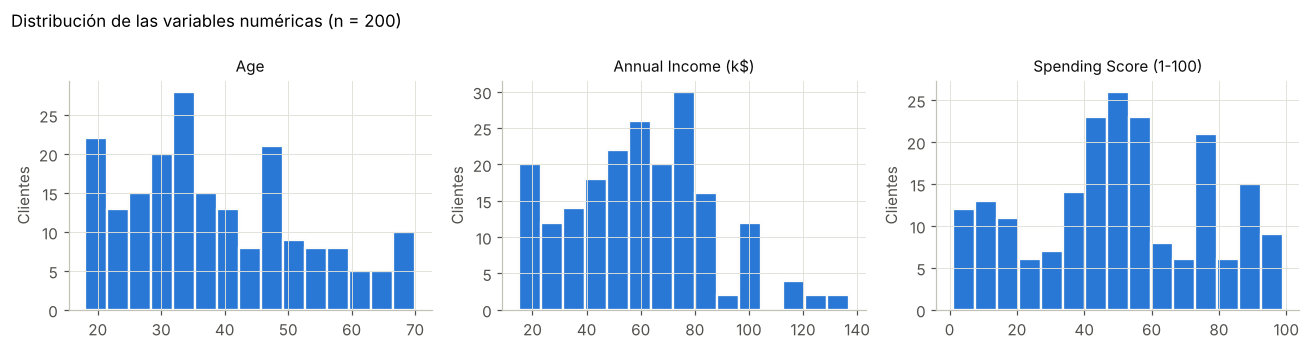

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, col in zip(ax, num.columns):
    a.hist(num[col], bins=15, color='#2a78d6', edgecolor='#fcfcfb', linewidth=1.5)
    a.set_title(col, fontsize=10, color='#0b0b0b'); a.set_ylabel('Clientes')
fig.suptitle('Distribución de las variables numéricas (n = 200)', fontsize=11, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(FIG / 'f1_distribuciones.png', dpi=160, bbox_inches='tight'); plt.show()

**Decisión G1 (aprobada):** sin nulos ni duplicados; «Unknown» = 13 % y 7,5 % (< 20 %), por lo que no se activa
la contingencia de datos. La correlación ingreso–gasto es 0,01: hay que agrupar con ambas variables a la vez.
Hay 2 ingresos atípicos (137 k$); se evalúa su efecto en el modelado antes de decidir.

## Fase 3 · Preparación (Sprint 3 → E3, puerta G2)
Se normalizan los nombres (la columna `'Education '` trae un espacio), «Unknown» queda como categoría explícita
y el `CustomerID` se reemplaza por un hash SHA-256 con sal (RNF3). El dataset preparado ya no contiene el ID original.

In [6]:
df = seg.preparar_datos(crudo)
df.to_csv(RAIZ / 'data/processed/clientes_preparados.csv', index=False)
print('Columnas:', list(df.columns))
print('¿Queda el CustomerID original?', 'customer_id' in df.columns)
df.head()

Columnas: ['id_anon', 'genero', 'edad', 'educacion', 'estado_civil', 'ingreso_anual_k', 'spending_score']
¿Queda el CustomerID original? False


,id_anon,genero,edad,educacion,estado_civil,ingreso_anual_k,spending_score
0,f304c1dc83da,M,19,High School,Married,15,39
1,5517ad09745e,M,21,Graduate,Single,15,81
2,977f31f5e44d,F,20,Graduate,Married,16,6
3,ab00d48d1df6,F,23,High School,Unknown,16,77
4,a4e497f05e8e,F,31,Uneducated,Married,17,40


In [7]:
diccionario = pd.DataFrame({
    'variable': df.columns,
    'tipo': [str(t) for t in df.dtypes],
    'uso': ['identificador anonimizado (listados)', 'auditoría', 'auditoría', 'auditoría', 'auditoría',
            'MODELO', 'MODELO'],
})
diccionario

,variable,tipo,uso
0,id_anon,str,identificador anonimizado (listados)
1,genero,str,auditoría
2,edad,int64,auditoría
3,educacion,str,auditoría
4,estado_civil,str,auditoría
5,ingreso_anual_k,int64,MODELO
6,spending_score,int64,MODELO


## Fase 4 · Modelado (Sprints 4–5 → E4, puerta G3)
Se evalúa k = 2 a 10 con el método del codo y el coeficiente Silhouette (RF2), con y sin estandarización.

In [8]:
X_bruto = df[seg.VARIABLES_MODELO].to_numpy(float)
X, scaler = seg.matriz_modelo(df)
curvas = seg.evaluar_k(X).merge(seg.evaluar_k(X_bruto)[['k', 'silhouette']], on='k', suffixes=('_std', '_sin_std'))
curvas.round(3)

,k,inercia,silhouette_std,silhouette_sin_std
0,2,269.691,0.321,0.297
1,3,157.704,0.467,0.468
2,4,108.921,0.494,0.493
3,5,65.568,0.555,0.554
4,6,55.057,0.540,0.540
5,7,44.865,0.528,0.529
6,8,37.228,0.455,0.455
7,9,32.392,0.457,0.456
8,10,29.982,0.443,0.441


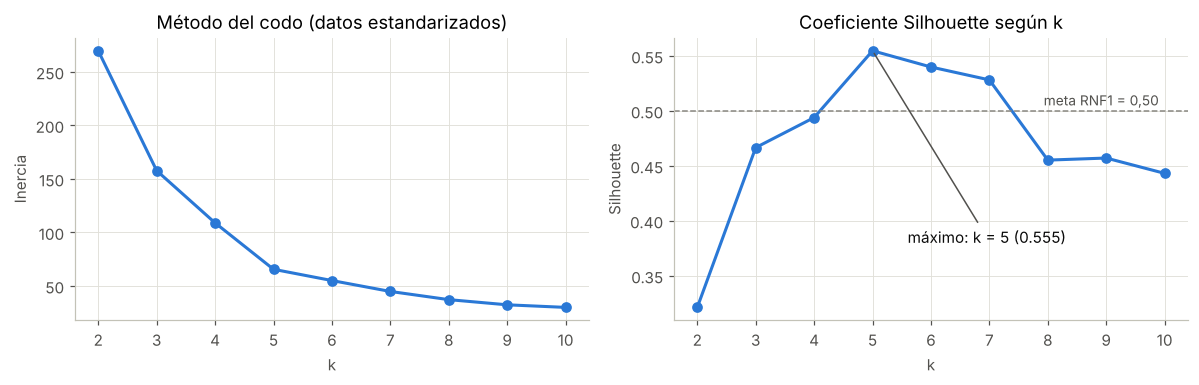

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(curvas.k, curvas.inercia, color='#2a78d6', lw=2, marker='o', ms=6)
a1.set(title='Método del codo (datos estandarizados)', xlabel='k', ylabel='Inercia')
a2.plot(curvas.k, curvas.silhouette_std, color='#2a78d6', lw=2, marker='o', ms=6)
a2.axhline(0.50, color='#898781', ls='--', lw=1); a2.text(9.9, 0.505, 'meta RNF1 = 0,50', ha='right', color='#52514e', fontsize=9)
best = curvas.loc[curvas.silhouette_std.idxmax()]
a2.annotate(f"máximo: k = 5 ({best.silhouette_std:.3f})", (best.k, best.silhouette_std), xytext=(5.6, 0.38),
            arrowprops=dict(arrowstyle='-', color='#52514e'), color='#0b0b0b')
a2.set(title='Coeficiente Silhouette según k', xlabel='k', ylabel='Silhouette')
for a in (a1, a2): a.set_xticks(range(2, 11))
fig.tight_layout(); fig.savefig(FIG / 'f2_codo_silhouette.png', dpi=160, bbox_inches='tight'); plt.show()

In [10]:
# Experimentos de control (registrados en la bitácora técnica)
lab_std = KMeans(5, random_state=42, n_init=10).fit_predict(X)
lab_bruto = KMeans(5, random_state=42, n_init=10).fit_predict(X_bruto)
print('1) Con vs. sin estandarización, ARI =', round(adjusted_rand_score(lab_std, lab_bruto), 3))

sin_atip = (df.ingreso_anual_k <= 132.75).to_numpy()
lab_sa = KMeans(5, random_state=42, n_init=10).fit_predict(X[sin_atip])
print('2) Sin los 2 atípicos: Silhouette =', round(silhouette_score(X[sin_atip], lab_sa), 3),
      '| ARI vs. modelo completo =', round(adjusted_rand_score(lab_std[sin_atip], lab_sa), 3))

X_edad = df[['edad'] + seg.VARIABLES_MODELO].to_numpy(float)
print('3) Agregando la edad (no permitido por RNF4): Silhouette =',
      round(silhouette_score(X_edad, KMeans(5, random_state=42, n_init=10).fit_predict(X_edad)), 3))

1) Con vs. sin estandarización, ARI = 1.0
2) Sin los 2 atípicos: Silhouette = 0.561 | ARI vs. modelo completo = 0.985
3) Agregando la edad (no permitido por RNF4): Silhouette = 0.444


**Decisiones:** (1) se usa estandarización porque produce exactamente la misma partición (ARI = 1) y deja el
modelo listo para datos nuevos en otra escala; (2) los 2 clientes de 137 k$ se mantienen: son reales y quitarlos
casi no cambia los grupos (ARI 0,985); (3) la edad no entra al modelo, por ética (RNF4) y porque baja la Silhouette.

In [11]:
modelo = seg.entrenar_modelo(X, k=5)
centroides = scaler.inverse_transform(modelo.cluster_centers_)
letras = seg.nombrar_segmentos(centroides)
df['segmento'] = pd.Series(modelo.labels_).map(letras).to_numpy()
sil = silhouette_score(X, modelo.labels_)
estab = seg.probar_estabilidad(X, 5, modelo.labels_)
print(f'Silhouette final = {sil:.3f}  (RNF1 >= 0,50: {"CUMPLE" if sil >= .5 else "NO CUMPLE"})')
print(f'ARI mínimo con 20 semillas = {estab.ARI.min():.3f}  (RNF2: {"CUMPLE" if estab.ARI.min() == 1 else "NO CUMPLE"})')
print('Tamaño de segmentos:', df.segmento.value_counts().sort_index().to_dict(),
      '| mínimo =', f'{df.segmento.value_counts().min()/len(df):.1%}', '(RNF1 >= 5 %)')
pd.DataFrame(centroides.round(1), columns=['ingreso_k', 'gasto']).assign(segmento=[letras[i] for i in range(5)]).set_index('segmento').sort_index()

Silhouette final = 0.555  (RNF1 >= 0,50: CUMPLE)
ARI mínimo con 20 semillas = 1.000  (RNF2: CUMPLE)
Tamaño de segmentos: {'A': 81, 'B': 39, 'C': 22, 'D': 35, 'E': 23} | mínimo = 11.0% (RNF1 >= 5 %)


,ingreso_k,gasto
segmento,,
A,55.3,49.5
B,86.5,82.1
C,25.7,79.4
D,88.2,17.1
E,26.3,20.9


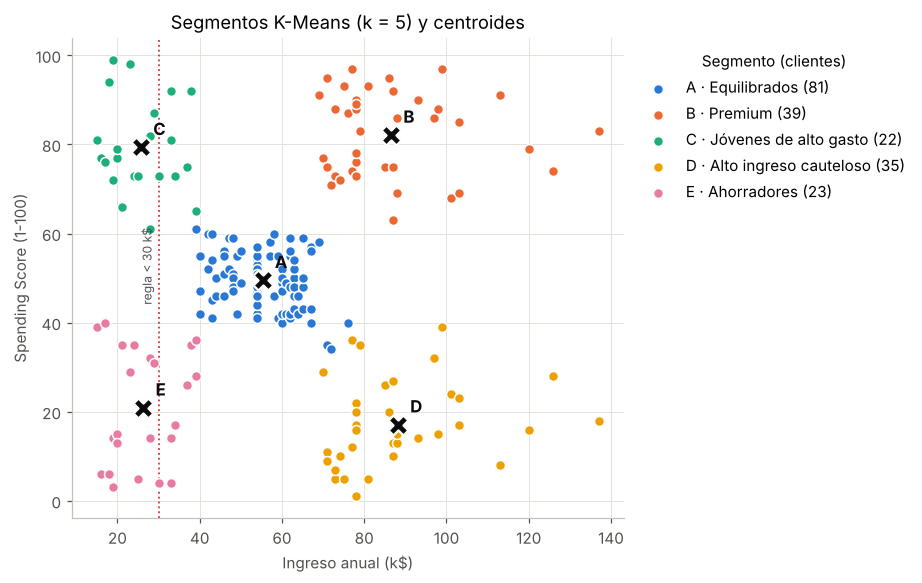

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 5.4))
for s in sorted(COLORES):
    d = df[df.segmento == s]
    ax.scatter(d.ingreso_anual_k, d.spending_score, s=42, color=COLORES[s], edgecolor='#fcfcfb', linewidth=1,
               label=f'{s} · {seg.SEGMENTOS[s]} ({len(d)})', zorder=3)
for i, (x, y) in enumerate(centroides):
    ax.scatter(x, y, s=170, marker='X', color='#0b0b0b', edgecolor='#fcfcfb', linewidth=1.5, zorder=4)
    ax.annotate(letras[i], (x, y), xytext=(8, 8), textcoords='offset points', fontsize=11, weight='bold', color='#0b0b0b')
ax.axvline(30, color='#d03b3b', ls=':', lw=1.2)
ax.text(29, 44, 'regla < 30 k$', rotation=90, ha='right', va='bottom', color='#52514e', fontsize=8)
ax.set(xlabel='Ingreso anual (k$)', ylabel='Spending Score (1-100)', title='Segmentos K-Means (k = 5) y centroides')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Segmento (clientes)')
fig.tight_layout(); fig.savefig(FIG / 'f3_segmentos.png', dpi=160, bbox_inches='tight'); plt.show()

### Validación con conjuntos de entrenamiento y prueba (80/20)
K-Means no tiene una variable objetivo que predecir: las variables independientes son ingreso y gasto y el
"resultado" es el segmento. Para revisar que el modelo generaliza, se entrena con el 80 % de los clientes y se
asigna el 20 % restante (40 clientes que el modelo no vio). Se compara la Silhouette en ambos conjuntos y si los
clientes de prueba caen en el mismo segmento que les da el modelo entrenado con los 200.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

train, test = train_test_split(df, test_size=0.2, random_state=42)
sc_tr = StandardScaler().fit(train[seg.VARIABLES_MODELO])          # el escalador se ajusta solo con entrenamiento
X_tr, X_te = sc_tr.transform(train[seg.VARIABLES_MODELO]), sc_tr.transform(test[seg.VARIABLES_MODELO])
m_tr = KMeans(5, random_state=42, n_init=10).fit(X_tr)
letras_tr = seg.nombrar_segmentos(sc_tr.inverse_transform(m_tr.cluster_centers_))
pred_test = pd.Series(m_tr.predict(X_te)).map(letras_tr).to_numpy()

print(f'Entrenamiento: {len(train)} clientes | Prueba: {len(test)} clientes')
print(f'Silhouette entrenamiento = {silhouette_score(X_tr, m_tr.labels_):.3f} | prueba = {silhouette_score(X_te, m_tr.predict(X_te)):.3f}')
print(f'Clientes de prueba en el mismo segmento que el modelo completo: {(pred_test == test.segmento.values).sum()} de {len(test)}')

acuerdos = []
for s in range(20):  # 20 particiones distintas para ver que no fue suerte
    tr, te = train_test_split(df, test_size=0.2, random_state=s)
    sc = StandardScaler().fit(tr[seg.VARIABLES_MODELO])
    m = KMeans(5, random_state=42, n_init=10).fit(sc.transform(tr[seg.VARIABLES_MODELO]))
    let = seg.nombrar_segmentos(sc.inverse_transform(m.cluster_centers_))
    p = pd.Series(m.predict(sc.transform(te[seg.VARIABLES_MODELO]))).map(let).to_numpy()
    acuerdos.append((p == te.segmento.values).mean())
print(f'Acuerdo en 20 particiones: mínimo {min(acuerdos):.1%}, promedio {np.mean(acuerdos):.1%}')

Entrenamiento: 160 clientes | Prueba: 40 clientes
Silhouette entrenamiento = 0.553 | prueba = 0.567
Clientes de prueba en el mismo segmento que el modelo completo: 40 de 40


Acuerdo en 20 particiones: mínimo 97.5%, promedio 99.5%


**Resultado:** el modelo entrenado con 160 clientes asigna a los 40 de prueba al mismo segmento que el modelo
completo y la Silhouette en prueba también supera 0,50. Con 20 particiones distintas el acuerdo nunca baja de 97,5 %,
por lo que la segmentación no depende de qué clientes se usen para entrenar.

## Fase 5 · Evaluación y auditoría ética (Sprint 6 → E5, puerta G4)

In [14]:
df = seg.aplicar_regla_credito(df)
perfil = seg.perfilar_segmentos(df)
perfil['silhouette_prom'] = pd.Series(silhouette_samples(X, modelo.labels_)).groupby(df.segmento.values).mean().round(3)
perfil

,nombre,clientes,pct_clientes,ingreso_prom_k,gasto_prom,edad_prom,edad_min,edad_max,pct_mujeres,ingreso_menor_30k,pct_educ_unknown,silhouette_prom
segmento,,,,,,,,,,,,
A,Equilibrados,81,40.5,55.3,49.5,42.7,18,70,59.3,0,14.8,0.598
B,Premium,39,19.5,86.5,82.1,32.7,27,40,53.8,0,10.3,0.511
C,Jóvenes de alto gasto,22,11.0,25.7,79.4,25.3,18,35,59.1,15,27.3,0.598
D,Alto ingreso cauteloso,35,17.5,88.2,17.1,41.1,19,59,45.7,0,2.9,0.505
E,Ahorradores,23,11.5,26.3,20.9,45.2,19,67,60.9,15,13.0,0.511


In [15]:
aud = seg.auditoria(df)
for var, tabla in aud.items():
    print(f'\n--- Composición (%) por {var} ---'); print(tabla.to_string())


--- Composición (%) por genero ---
genero       F     M
segmento            
A         59.3  40.7
B         53.8  46.2
C         59.1  40.9
D         45.7  54.3
E         60.9  39.1

--- Composición (%) por tramo_edad ---
tramo_edad  18-29  30-44  45-59   60+
segmento                             
A            29.6   18.5   32.1  19.8
B            20.5   79.5    0.0   0.0
C            72.7   27.3    0.0   0.0
D            14.3   45.7   40.0   0.0
E             8.7   34.8   39.1  17.4

--- Composición (%) por educacion ---
educacion  College  Doctorate  Graduate  High School  Post-Graduate  Uneducated  Unknown
segmento                                                                                
A              6.2        7.4      38.3         19.8            3.7         9.9     14.8
B             10.3        5.1      33.3         15.4            5.1        20.5     10.3
C              9.1        4.5      31.8         18.2            0.0         9.1     27.3
D             11.4        2

In [16]:
fuera = df[~df.apto_promo_credito]
print('Clientes excluidos de promociones de crédito (RF5):', len(fuera), '| por segmento:', fuera.segmento.value_counts().sort_index().to_dict())
alerta = perfil[perfil.pct_educ_unknown > 20]
print('Señal de riesgo R2 (>20 % Unknown en educación):', alerta.index.tolist(), alerta.pct_educ_unknown.tolist())

Clientes excluidos de promociones de crédito (RF5): 30 | por segmento: {'C': 15, 'E': 15}
Señal de riesgo R2 (>20 % Unknown en educación): ['C'] [27.3]


**Resultado G4:** RNF4 cumple (solo ingreso y gasto en el `fit`), la regla < 30 k$ deja fuera a 30 clientes
(15 de C y 15 de E) y el segmento C activa la señal del riesgo R2 (27,3 % de educación «Unknown»): su ficha no se
apoya en la educación. Las diferencias de género entre segmentos son moderadas (46 % a 61 % de mujeres).

## Fase 6 · Despliegue: modelo, listados y asignación de clientes nuevos (Sprints 7–9 → E6, E7)

In [17]:
import joblib
joblib.dump({'modelo': modelo, 'scaler': scaler, 'letras': letras, 'variables': seg.VARIABLES_MODELO},
            RAIZ / 'models/kmeans_k5.joblib')
cols = ['id_anon', 'segmento', 'ingreso_anual_k', 'spending_score', 'apto_promo_credito']
salida = RAIZ / 'outputs/listados'
for s, g in df.groupby('segmento'):
    g[cols].to_csv(salida / f'listado_segmento_{s}.csv', index=False)
    g.loc[g.apto_promo_credito, cols].to_csv(salida / f'listado_credito_segmento_{s}.csv', index=False)
print(sorted(p.name for p in salida.glob('*.csv')))
pd.read_csv(salida / 'listado_credito_segmento_C.csv')

['listado_credito_segmento_A.csv', 'listado_credito_segmento_B.csv', 'listado_credito_segmento_C.csv', 'listado_credito_segmento_D.csv', 'listado_credito_segmento_E.csv', 'listado_segmento_A.csv', 'listado_segmento_B.csv', 'listado_segmento_C.csv', 'listado_segmento_D.csv', 'listado_segmento_E.csv']


,id_anon,segmento,ingreso_anual_k,spending_score,apto_promo_credito
0,d4afa3476ebe,C,30,73,True
1,31198ffa3c7c,C,33,92,True
2,4eddd8157da1,C,33,81,True
3,5ac7e5477dc7,C,34,73,True
4,68a1118860e2,C,37,75,True
5,0ebfaa22d587,C,38,92,True
6,faeafa0ff974,C,39,65,True


In [18]:
# RF8: cinco clientes nuevos de la tarjeta (datos ficticios de prueba), asignados por lote con el modelo guardado
from asignar_nuevos import asignar
nuevos = pd.DataFrame({'CustomerID': [201, 202, 203, 204, 205],
                       'Annual Income (k$)': [20, 120, 60, 95, 25],
                       'Spending Score (1-100)': [85, 15, 55, 90, 10]})
pred = asignar(nuevos)
pred.insert(0, 'cliente', nuevos['CustomerID'].to_numpy())  # solo para leer la tabla; los listados usan id_anon
pred

,cliente,id_anon,segmento,ingreso_anual_k,spending_score,apto_promo_credito
0,201,5ae25dc8358c,C,20,85,False
1,202,7c600bafb6e5,D,120,15,True
2,203,7319b966ce2b,A,60,55,True
3,204,30a22cdb3dfc,B,95,90,True
4,205,8b863d8fd9d1,E,25,10,False


In [19]:
# Pruebas de aceptación automáticas (tests/test_reglas.py)
import subprocess
print(subprocess.run([sys.executable, str(RAIZ / 'src/pipeline.py')], capture_output=True, text=True).stdout[-160:])
print(subprocess.run([sys.executable, str(RAIZ / 'tests/test_reglas.py')], capture_output=True, text=True).stdout)

: 1.0,
  "cumple_RNF1": true,
  "cumple_RNF2": true,
  "clientes_excluidos_credito": 30,
  "variables_fit": [
    "ingreso_anual_k",
    "spending_score"
  ]
}



OK  test_rnf1_calidad
OK  test_rnf2_estabilidad
OK  test_rnf4_sin_demograficas_en_fit
OK  test_rf5_ningun_cliente_bajo_30k_en_listados_de_credito
OK  test_rf5_30_casos_excluidos
OK  test_rnf3_sin_identificadores_originales
OK  test_rf1_todos_los_clientes_con_segmento
7 pruebas aprobadas



## Resumen de cumplimiento
| Requerimiento | Resultado | Estado |
|---|---|---|
| RF1 · 200 clientes con segmento (solo ingreso y gasto) | 200/200 | ✅ |
| RF2 · k justificado con codo y Silhouette (k = 2..10) | k = 5 | ✅ |
| RNF1 · Silhouette ≥ 0,50 y segmento mínimo ≥ 5 % | 0,555 y 11 % | ✅ |
| RNF2 · Misma asignación con 20 semillas | ARI = 1,000 | ✅ |
| Validación 80/20 · clientes de prueba en el mismo segmento | 40 de 40 | ✅ |
| RNF3 · Sin CustomerID original en datos y listados | 0 encontrados | ✅ |
| RNF4 · Sin demográficas en el entrenamiento | 0 | ✅ |
| RF5 · Regla < 30 k$ en listados de crédito | 30 excluidos, 0 incumplimientos | ✅ |
| RF8 (Could) · Asignación de clientes nuevos por lote | 5 predicciones con `src/asignar_nuevos.py` | ✅ |